# Sentiment Analysis of Tweets with PySpark (Sentiment140)
Exported from the original Databricks notebook, including its saved outputs.

### Installing Libraries

In [ ]:
# Install required libraries
%pip install pyspark wordcloud matplotlib pandas scikit-learn nltk
%pip install Pillow --upgrade


Python interpreter will be restarted.
... [11 lines omitted] ...
  Created wheel for pyspark: filename=pyspark-3.5.4-py2.py3-none-any.whl size=317849792 sha256=6600bd8b0d16ea3eed24e22574679dfc394ef86b19bacbf2cc1432bd5c088386
  Stored in directory: /root/.cache/pip/wheels/b9/0f/0a/1bf9096f5b49f278182d7fe905a82209f2090edb24a7352b72
Successfully built pyspark
Python interpreter will be restarted.
Python interpreter will be restarted.
  Attempting uninstall: Pillow
    Found existing installation: Pillow 9.0.1
    Not uninstalling pillow at /databricks/python3/lib/python3.9/site-packages, outside environment /local_disk0/.ephemeral_nfs/envs/pythonEnv-a7984579-063f-4f15-bd58-798727519d08
    Can't uninstall 'Pillow'. No files were found to uninstall.
Python interpreter will be restarted.



### Importing Libraries

In [ ]:
# Import necessary libraries
import re
import nltk
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StringType
from pyspark.ml.feature import Tokenizer, CountVectorizer, IDF
from pyspark.ml.classification import LogisticRegression, NaiveBayes
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Download NLTK stopwords
nltk.download("stopwords")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.



Out[1]: True


### Initializing the Spark Session and Loading the Dataset

In [ ]:
# Initialize Spark session
spark = SparkSession.builder.appName("SentimentAnalysisTask").getOrCreate()

# Load dataset from file store
data_path = "/FileStore/tables/training_1600000_processed_noemoticon.csv"
data = spark.read.csv(data_path, inferSchema=True)

# Rename important columns for clarity
data = data.withColumnRenamed("_c0", "target").withColumnRenamed("_c5", "tweet")


### Mapping Sentiment Labels to Binary Values

In [ ]:
# Map target values to binary labels
data = data.withColumn("label", (F.col("target") / 4).cast("double")).drop("target")

# Text cleaning setup
stopwords_list = stopwords.words("english")
stemmer = SnowballStemmer("english")
regex_cleaning = r"@\S+|https?:\S+|http?:\S|[^A-Za-z0-9]+"

def clean_text_content(text):
    # Handle HTML entities like &amp; and &quot;
    text = re.sub(r"&amp;", " ", text)
    text = re.sub(r"&quot;", " ", text)
    # Remove unwanted characters and lower the text
    cleaned = re.sub(regex_cleaning, " ", str(text).lower()).strip()
    # Tokenize, Remove Stopwords, and Stem
    tokens = [stemmer.stem(token) for token in cleaned.split() if token not in stopwords_list]
    return " ".join(tokens)

# Create UDF (User-Defined Function) for text preprocessing
clean_text_udf = F.udf(lambda txt: clean_text_content(txt), StringType())
data = data.withColumn("processed_text", clean_text_udf(F.col("tweet"))).drop("tweet")

# Display data table
data.show()


+----------+--------------------+--------+---------------+-----+--------------------+
|       _c1|                 _c2|     _c3|            _c4|label|      processed_text|
+----------+--------------------+--------+---------------+-----+--------------------+
|1467810369|Mon Apr 06 22:19:...|NO_QUERY|_TheSpecialOne_|  0.0|awww bummer shoul...|
|1467810672|Mon Apr 06 22:19:...|NO_QUERY|  scotthamilton|  0.0|upset updat faceb...|
|1467810917|Mon Apr 06 22:19:...|NO_QUERY|       mattycus|  0.0|dive mani time ba...|
|1467811184|Mon Apr 06 22:19:...|NO_QUERY|        ElleCTF|  0.0|whole bodi feel i...|
|1467811193|Mon Apr 06 22:19:...|NO_QUERY|         Karoli|  0.0|       behav mad see|
|1467811372|Mon Apr 06 22:20:...|NO_QUERY|       joy_wolf|  0.0|          whole crew|
|1467811592|Mon Apr 06 22:20:...|NO_QUERY|        mybirch|  0.0|            need hug|
|1467811594|Mon Apr 06 22:20:...|NO_QUERY|           coZZ|  0.0|hey long time see...|
|1467811795|Mon Apr 06 22:20:...|NO_QUERY|2Hood4Hollyw

### Visualizing the Data Using Word Clouds

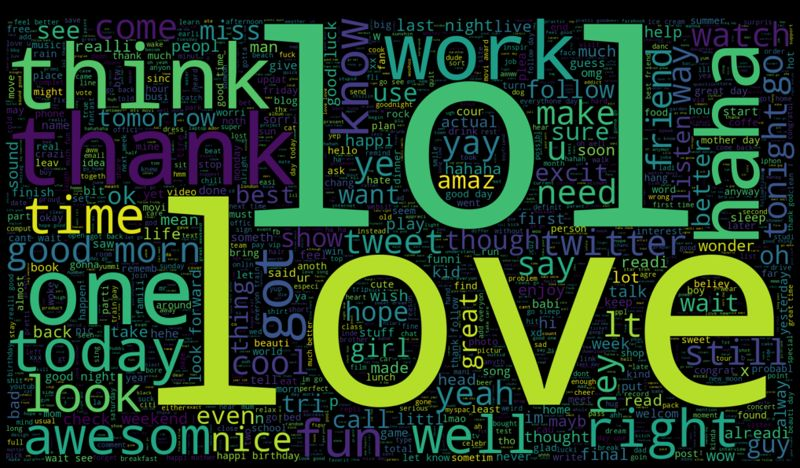

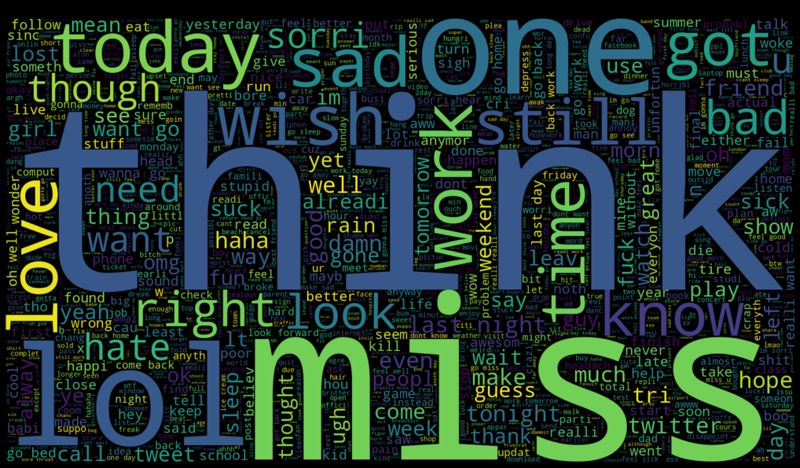

In [ ]:
# Convert Spark DataFrame to Pandas for visualization
pandas_data = data.toPandas()

# Positive sentiment word cloud
plt.figure(figsize=(18, 14))
positive_words = " ".join(pandas_data[pandas_data["label"] == 1.0].processed_text)
pos_wc = WordCloud(max_words=1500, width=1600, height=900).generate(positive_words)
plt.imshow(pos_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Positive Sentiments")
plt.show()

# Negative sentiment word cloud
plt.figure(figsize=(18, 14))
negative_words = " ".join(pandas_data[pandas_data["label"] == 0.0].processed_text)
neg_wc = WordCloud(max_words=1500, width=1600, height=900).generate(negative_words)
plt.imshow(neg_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Negative Sentiments")
plt.show()


### Tokenizing, Vectorizing, and Computing TF-IDF

In [ ]:
# Tokenize processed text
tokenizer = Tokenizer(inputCol="processed_text", outputCol="tokenized_words")
data_tokenized = tokenizer.transform(data)

# Vectorize tokens into raw counts
vectorizer = CountVectorizer(inputCol="tokenized_words", outputCol="raw_features")
cv_model = vectorizer.fit(data_tokenized)
raw_data_features = cv_model.transform(data_tokenized)

#Display
raw_data_features.show()

# Compute TF-IDF features
idf_transformer = IDF(inputCol="raw_features", outputCol="features")
idf_model = idf_transformer.fit(raw_data_features)
data_final = idf_model.transform(raw_data_features).select("label", "features")

# Display
data_final.show()



+----------+--------------------+--------+---------------+-----+--------------------+--------------------+--------------------+
|       _c1|                 _c2|     _c3|            _c4|label|      processed_text|     tokenized_words|        raw_features|
+----------+--------------------+--------+---------------+-----+--------------------+--------------------+--------------------+
|1467810369|Mon Apr 06 22:19:...|NO_QUERY|_TheSpecialOne_|  0.0|awww bummer shoul...|[awww, bummer, sh...|(262144,[2,9,366,...|
|1467810672|Mon Apr 06 22:19:...|NO_QUERY|  scotthamilton|  0.0|upset updat faceb...|[upset, updat, fa...|(262144,[7,74,189...|
|1467810917|Mon Apr 06 22:19:...|NO_QUERY|       mattycus|  0.0|dive mani time ba...|[dive, mani, time...|(262144,[0,8,226,...|
|1467811184|Mon Apr 06 22:19:...|NO_QUERY|        ElleCTF|  0.0|whole bodi feel i...|[whole, bodi, fee...|(262144,[5,19,344...|
|1467811193|Mon Apr 06 22:19:...|NO_QUERY|         Karoli|  0.0|       behav mad see|   [behav, mad, see

### Splitting into Training and Testing

In [ ]:
# Train-test split
training_data, testing_data = data_final.randomSplit([0.9, 0.1], seed=24)


### Using Machine Learning Models

In [ ]:
# Train Logistic Regression model
log_reg = LogisticRegression(labelCol="label", featuresCol="features", maxIter=12)
log_reg_model = log_reg.fit(training_data)
log_reg_preds = log_reg_model.transform(testing_data)

# Train Naive Bayes model
naive_bayes = NaiveBayes(labelCol="label", featuresCol="features")
nb_model = naive_bayes.fit(training_data)
nb_preds = nb_model.transform(testing_data)


### Evaluating ML Models

In [ ]:
# Evaluation function for metrics and confusion matrix
def evaluate_models(predictions_dict):
    for name, preds in predictions_dict.items():
        preds_df = preds.select("label", "prediction").toPandas()
        y_actual = preds_df["label"]
        y_pred = preds_df["prediction"]

        # Calculate metrics
        eval_report = classification_report(y_actual, y_pred, output_dict=True)
        accuracy = accuracy_score(y_actual, y_pred)
        confusion = confusion_matrix(y_actual, y_pred)

        # Display metrics
        print(f"==== {name} ====")
        print(f"Accuracy: {accuracy:.3f}")
        print(f"Precision: {eval_report['1.0']['precision']:.3f}")
        print(f"Recall: {eval_report['1.0']['recall']:.3f}")
        print(f"F1-Score: {eval_report['1.0']['f1-score']:.3f}")
        print(f"Confusion Matrix:\n{confusion}\n")

# Compare models
evaluate_models({"Logistic Regression": log_reg_preds, "Naive Bayes": nb_preds})


==== Logistic Regression ====
Accuracy: 0.760
Precision: 0.753
Recall: 0.777
F1-Score: 0.765
Confusion Matrix:
[[59421 20496]
 [17939 62437]]

==== Naive Bayes ====
Accuracy: 0.744
Precision: 0.754
Recall: 0.727
F1-Score: 0.740
Confusion Matrix:
[[60806 19111]
 [21911 58465]]




### Visualizing the Confusion Matrices

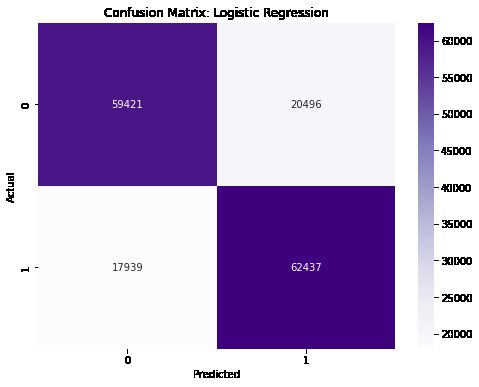

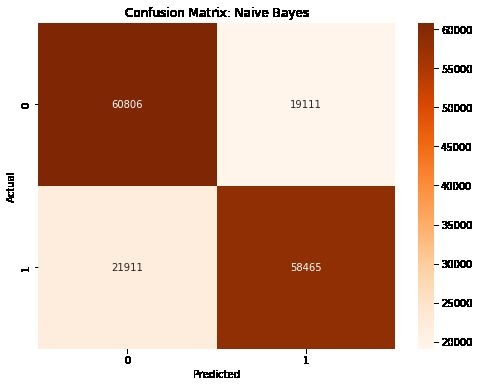

In [ ]:
# Visualize Logistic Regression confusion matrix
lr_cm = confusion_matrix(
    log_reg_preds.select("label", "prediction").toPandas()["label"],
    log_reg_preds.select("label", "prediction").toPandas()["prediction"]
)
plt.figure(figsize=(8, 6))
sns.heatmap(lr_cm, annot=True, cmap="Purples", fmt="d")
plt.title("Confusion Matrix: Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Visualize Naive Bayes confusion matrix
nb_cm = confusion_matrix(
    nb_preds.select("label", "prediction").toPandas()["label"],
    nb_preds.select("label", "prediction").toPandas()["prediction"]
)
plt.figure(figsize=(8, 6))
sns.heatmap(nb_cm, annot=True, cmap="Oranges", fmt="d")
plt.title("Confusion Matrix: Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
